# GAT-v4 | Phase 7E — Comparison Figures (Literature Baselines + Ablation Studies)

**Companion to Phase 7C (SOTA comparison) and Phase 7D (ablation studies).** Generates the two
publication-ready figures most manuscripts need for a "comparison to prior work" and "ablation study"
section:

1. **Literature baseline figure** — Cox-GAT's internal C-index plotted against five literature-reported
   graph-based survival methods (GraphSAGE-surv, GCN-surv, FGCNSurv, GAT-surv, MLP-surv — all Kim et al.
   2023 / Yang et al. 2023), with the literature bars visually distinguished from the in-pipeline result to
   avoid implying a controlled comparison.
2. **Ablation contribution figure** — a horizontal tornado/bar chart of the five most damaging ablations
   (no_clinical, hidden_128, no_residual, random_graph, no_degree), showing delta C-index relative to the
   full re-trained GATv4 reference.

### Data sources (read-only — this notebook does not retrain anything)
- `results/tables/literature_context_sota.csv` (Phase 7C, Cell 10)
- `results/tables/cv_results.csv` (Phase 7, Cell 8) — Cox-GAT's own internal result
- `results/tables/ablation_summary.csv` (Phase 7D, Cell 8)

### Transparency convention carried over from Phase 7C
Every figure and caption in this notebook follows the same rule used throughout this project:
literature-reported numbers are never visually or textually implied to have been reproduced on this
pipeline's data. The literature figure uses a distinct color/hatch pattern and an explicit caption stating
the values are as published, not re-run.

---
| Cell | What |
|------|------|
| 1 | Imports & paths |
| 2 | Load literature context + Cox-GAT's own result (Phase 7/7C outputs) |
| 3 | Figure 1 — Cox-GAT vs. literature-reported graph-based methods |
| 4 | Load ablation summary, select the 5 requested ablations (Phase 7D output) |
| 5 | Figure 2 — Ablation contribution (tornado chart) |
| 6 | Combined summary table (both figures' underlying data, for the caption/appendix) |

---
## Cell 1 — Imports & Paths

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── PATHS (same layout as Phase 7 / 7C / 7D) ────────────────────────────────────────────
PROJECT_ROOT = Path(r"C:\Users\jiyad\Desktop\PROJECT\KIRC\script")
KIRC_ROOT = PROJECT_ROOT / "KIRC"
TABLE_DIR = KIRC_ROOT / "results" / "tables"
FIGURE_DIR = KIRC_ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
# ──────────────────────────────────────────────────────────────────────────

plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.family': 'serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

print(f"Table dir  : {TABLE_DIR}")
print(f"Figure dir : {FIGURE_DIR}")

Table dir  : C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\tables
Figure dir : C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\figures


---
## Cell 2 — Load Literature Context + Cox-GAT's Own Result

Reads `literature_context_sota.csv` (written by Phase 7C, Cell 10) and filters to exactly the five
requested methods. Cox-GAT's own internal mean C-index is loaded separately from `cv_results.csv`
(Phase 7's own output) rather than hardcoded, so the figure always reflects the latest completed
training run.

In [2]:
LITERATURE_METHODS = [
    'GraphSAGE-surv (Kim et al. 2023)',
    'GCN-surv (Kim et al. 2023)',
    'FGCNSurv (Yang et al. 2023)',
    'GAT-surv (Kim et al. 2023)',
    'MLP-surv (Kim et al. 2023, GNN-surv paper)',
]

lit_path = TABLE_DIR / 'literature_context_sota.csv'
if not lit_path.exists():
    raise FileNotFoundError(
        f"{lit_path} not found -- run Phase 7C (Cell 10) first to generate the literature context table."
    )
lit_df = pd.read_csv(lit_path)

lit_df = lit_df[lit_df['method'].isin(LITERATURE_METHODS)].copy()
missing = set(LITERATURE_METHODS) - set(lit_df['method'])
if missing:
    print(f"WARNING: {missing} not found in literature_context_sota.csv -- check method name spelling.")

def parse_reported_value(s):
    """Extract the leading float from strings like '0.7099' or '0.740 (best dataset)'.
    Returns NaN for non-numeric entries (there are none among the 5 requested methods,
    but this guards against a future literature_context edit that adds one).
    """
    import re
    m = re.match(r'[-+]?\d*\.?\d+', str(s).strip())
    return float(m.group()) if m else np.nan

lit_df['reported_value_numeric'] = lit_df['reported_value'].apply(parse_reported_value)

cv_results_path = TABLE_DIR / 'cv_results.csv'
if not cv_results_path.exists():
    raise FileNotFoundError(f"{cv_results_path} not found -- run Phase 7 first to produce Cox-GAT's own result.")
cv_results_df = pd.read_csv(cv_results_path)
gatv4_cindex = float(cv_results_df['test_cindex'].mean())
gatv4_std = float(cv_results_df['test_cindex'].std())

print(f"Cox-GAT internal mean C-index (this study, same 15 folds): {gatv4_cindex:.4f} (SD {gatv4_std:.4f})")
print()
print(lit_df[['method', 'cohort', 'metric', 'reported_value', 'reported_value_numeric']].to_string(index=False))

Cox-GAT internal mean C-index (this study, same 15 folds): 0.7697 (SD 0.0458)

                                    method                                cohort                      metric                 reported_value  reported_value_numeric
MLP-surv (Kim et al. 2023, GNN-surv paper)   TCGA-KIRC (n=313, same cancer type) Ctd (discrete-time C-index)                         0.6581                  0.6581
                GCN-surv (Kim et al. 2023)   TCGA-KIRC (n=313, same cancer type)                         Ctd                         0.7077                  0.7077
          GraphSAGE-surv (Kim et al. 2023)   TCGA-KIRC (n=313, same cancer type)                         Ctd 0.7099 (best reported on KIRC)                  0.7099
                GAT-surv (Kim et al. 2023)   TCGA-KIRC (n=313, same cancer type)                         Ctd                         0.6962                  0.6962
               FGCNSurv (Yang et al. 2023) TCGA pan-cancer + PCAWG (11 datasets)                     

---
## Cell 3 — Figure 1: Cox-GAT vs. Literature-Reported Graph-Based Methods

Cox-GAT's bar is drawn in a distinct solid color; every literature bar uses a hatched pattern and a
lighter shade specifically so the figure itself signals "not the same experiment" even before a reader
reaches the caption. The metric differs across rows (Ctd vs. C-index) — both are C-index variants
(discrete-time vs. continuous-time concordance) and are plotted on the same axis with the metric name
annotated per bar, consistent with how Table 7 in the manuscript addendum already presents them side by
side.

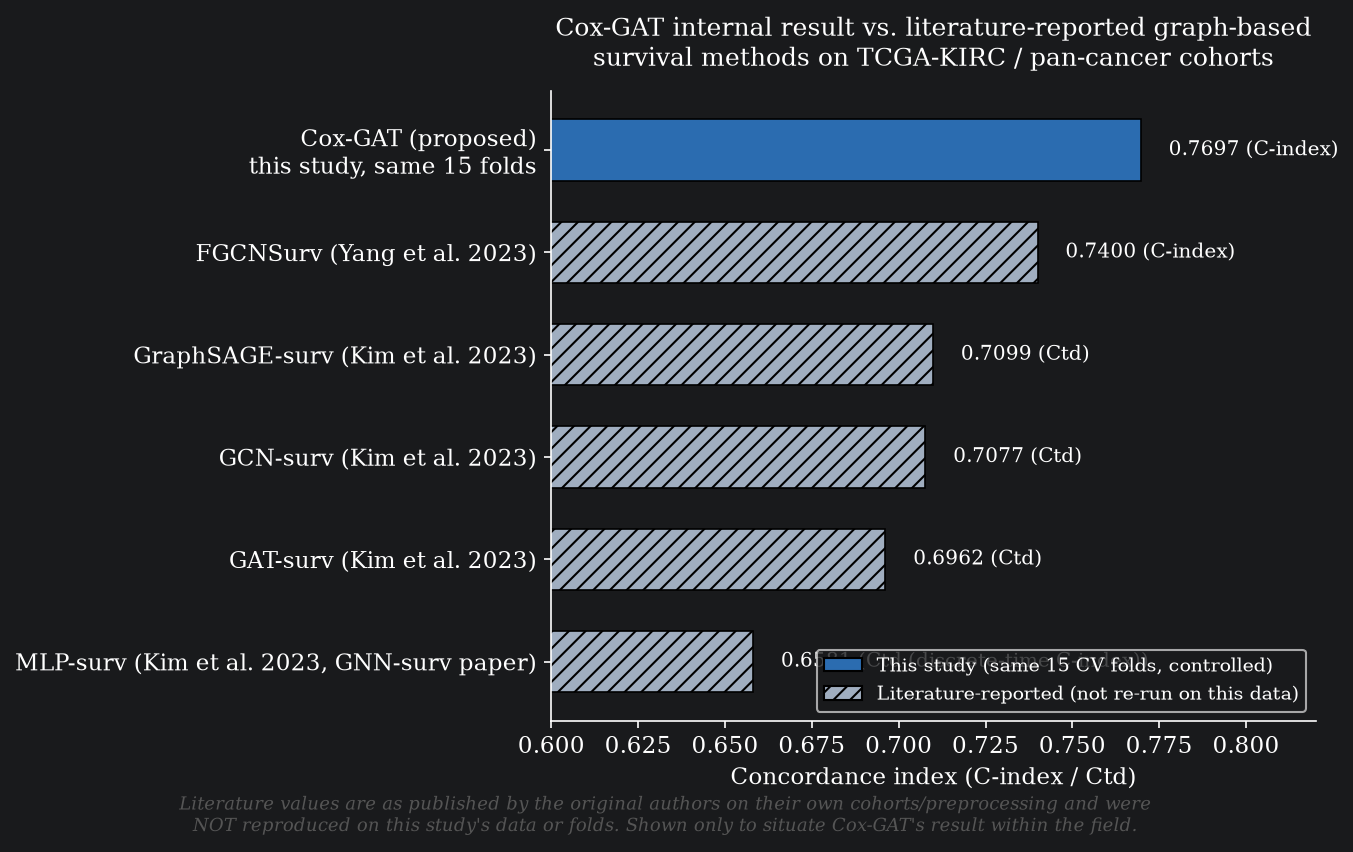

Saved -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\figures\fig_literature_comparison.png


In [3]:
plot_df = pd.concat([
    pd.DataFrame([{
        'method': 'Cox-GAT (proposed)\nthis study, same 15 folds',
        'value': gatv4_cindex, 'metric': 'C-index', 'is_literature': False,
    }]),
    lit_df.rename(columns={'reported_value_numeric': 'value'})[['method', 'value', 'metric']].assign(is_literature=True),
], ignore_index=True).sort_values('value', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5.5))

colors = ['#2b6cb0' if not lit else '#a0aec0' for lit in plot_df['is_literature']]
hatches = [None if not lit else '///' for lit in plot_df['is_literature']]

bars = ax.barh(plot_df['method'], plot_df['value'], color=colors, edgecolor='black', linewidth=0.8, height=0.6)
for bar, hatch in zip(bars, hatches):
    if hatch:
        bar.set_hatch(hatch)

for i, (val, metric) in enumerate(zip(plot_df['value'], plot_df['metric'])):
    ax.text(val + 0.008, i, f"{val:.4f} ({metric})", va='center', fontsize=9.5)

ax.set_xlabel('Concordance index (C-index / Ctd)')
ax.set_xlim(0.60, 0.82)
ax.set_title('Cox-GAT internal result vs. literature-reported graph-based\nsurvival methods on TCGA-KIRC / pan-cancer cohorts', fontsize=12, pad=12)

legend_patches = [
    mpatches.Patch(facecolor='#2b6cb0', edgecolor='black', label='This study (same 15 CV folds, controlled)'),
    mpatches.Patch(facecolor='#a0aec0', edgecolor='black', hatch='///', label='Literature-reported (not re-run on this data)'),
]
ax.legend(handles=legend_patches, loc='lower right', fontsize=9, frameon=True)

fig.text(0.5, -0.02,
         'Literature values are as published by the original authors on their own cohorts/preprocessing and were\n'
         'NOT reproduced on this study\'s data or folds. Shown only to situate Cox-GAT\'s result within the field.',
         ha='center', fontsize=8.5, style='italic', color='#555555')

plt.tight_layout()
fig1_path = FIGURE_DIR / 'fig_literature_comparison.png'
plt.savefig(fig1_path, bbox_inches='tight')
plt.show()
print(f"Saved -> {fig1_path}")

---
## Cell 4 — Load Ablation Summary, Select the 5 Requested Ablations

Reads `ablation_summary.csv` (Phase 7D, Cell 8) and filters to exactly the five ablations requested:
`no_clinical`, `hidden_128`, `no_residual`, `random_graph`, `no_degree`. These are the five largest
C-index reductions from the full 20-variant sweep, so filtering to just these five automatically produces
the "which components matter most" figure without needing to re-rank anything.

In [4]:
ABLATION_SELECTION = ['no_clinical', 'hidden_128', 'no_residual', 'random_graph', 'no_degree']

abl_path = TABLE_DIR / 'ablation_summary.csv'
if not abl_path.exists():
    raise FileNotFoundError(f"{abl_path} not found -- run Phase 7D (Cell 8) first to generate the ablation summary.")
abl_df = pd.read_csv(abl_path)

abl_selected = abl_df[abl_df['ablation'].isin(ABLATION_SELECTION)].copy()
missing_abl = set(ABLATION_SELECTION) - set(abl_selected['ablation'])
if missing_abl:
    print(f"WARNING: {missing_abl} not found in ablation_summary.csv -- check Phase 7D completed these ablations.")

full_row = abl_df[abl_df['ablation'] == 'full_gatv4']
if len(full_row) == 0:
    raise RuntimeError("full_gatv4 reference row missing from ablation_summary.csv.")
full_cindex = float(full_row.iloc[0]['mean_cindex'])
full_ibs = float(full_row.iloc[0]['mean_ibs'])
full_iauc = float(full_row.iloc[0]['mean_iauc'])

ABLATION_LABELS = {
    'no_clinical':   'no_clinical\n(remove age/stage/grade)',
    'hidden_128':    'hidden_128\n(double hidden width)',
    'no_residual':   'no_residual\n(remove skip connection)',
    'random_graph':  'random_graph\n(rewired PPI, matched density)',
    'no_degree':     'no_degree\n(remove degree feature)',
}
abl_selected['label'] = abl_selected['ablation'].map(ABLATION_LABELS)
abl_selected = abl_selected.sort_values('delta_cindex', ascending=True).reset_index(drop=True)

print(f"Full re-trained reference: C-index={full_cindex:.4f}, IBS={full_ibs:.4f}, iAUC={full_iauc:.4f}")
print()
print(abl_selected[['ablation', 'category', 'mean_cindex', 'delta_cindex', 'mean_ibs', 'delta_ibs', 'mean_iauc', 'delta_iauc']].to_string(index=False))

Full re-trained reference: C-index=0.7698, IBS=0.1615, iAUC=0.7912

    ablation       category  mean_cindex  delta_cindex  mean_ibs  delta_ibs  mean_iauc  delta_iauc
 no_clinical     A_features       0.6575       -0.1123    0.1804     0.0189     0.7155     -0.0757
  hidden_128     E_capacity       0.7459       -0.0239    0.1677     0.0062     0.7655     -0.0257
 no_residual C_architecture       0.7465       -0.0233    0.1671     0.0056     0.7642     -0.0270
random_graph        B_graph       0.7493       -0.0205    0.1653     0.0038     0.7729     -0.0183
   no_degree     A_features       0.7544       -0.0154    0.1696     0.0081     0.7708     -0.0204


---
## Cell 5 — Figure 2: Ablation Contribution (Tornado Chart)

A horizontal tornado chart of ΔC-index for the five selected ablations, all measured relative to the
`full_gatv4` reference re-trained in the same Phase 7D sweep (dashed zero-line). Bars are colored by
ablation category so the reader can see at a glance which axis (feature channels, architecture, graph
structure, capacity) each result belongs to.

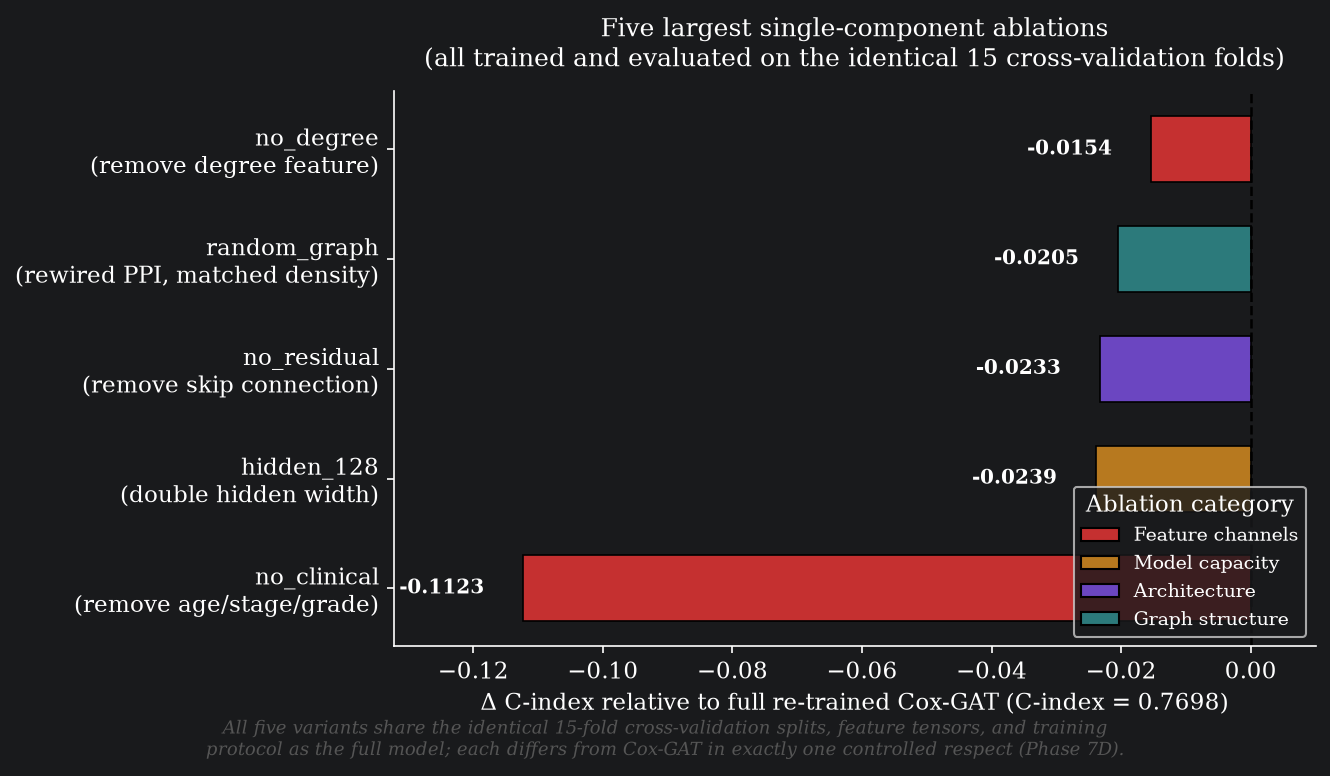

Saved -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\figures\fig_ablation_top5.png


In [5]:
CATEGORY_COLORS = {
    'A_features': '#c53030',
    'B_graph': '#2c7a7b',
    'C_architecture': '#6b46c1',
    'E_capacity': '#b7791f',
}
CATEGORY_LABELS = {
    'A_features': 'Feature channels',
    'B_graph': 'Graph structure',
    'C_architecture': 'Architecture',
    'E_capacity': 'Model capacity',
}

fig, ax = plt.subplots(figsize=(9, 5))

colors = abl_selected['category'].map(CATEGORY_COLORS)
bars = ax.barh(abl_selected['label'], abl_selected['delta_cindex'], color=colors, edgecolor='black', linewidth=0.8, height=0.6)

for i, (val, ) in enumerate(zip(abl_selected['delta_cindex'])):
    offset = -0.006 if val < 0 else 0.006
    ha = 'right' if val < 0 else 'left'
    ax.text(val + offset, i, f"{val:+.4f}", va='center', ha=ha, fontsize=9.5, fontweight='bold')

ax.axvline(0, color='black', linewidth=1.2, linestyle='--')
ax.set_xlabel(f'Δ C-index relative to full re-trained Cox-GAT (C-index = {full_cindex:.4f})')
ax.set_title('Five largest single-component ablations\n(all trained and evaluated on the identical 15 cross-validation folds)', fontsize=12, pad=12)
ax.set_xlim(min(abl_selected['delta_cindex']) - 0.02, 0.01)

used_categories = abl_selected['category'].unique()
legend_patches = [mpatches.Patch(facecolor=CATEGORY_COLORS[c], edgecolor='black', label=CATEGORY_LABELS[c]) for c in used_categories]
ax.legend(handles=legend_patches, loc='lower right', fontsize=9, frameon=True, title='Ablation category')

fig.text(0.5, -0.02,
         'All five variants share the identical 15-fold cross-validation splits, feature tensors, and training\n'
         'protocol as the full model; each differs from Cox-GAT in exactly one controlled respect (Phase 7D).',
         ha='center', fontsize=8.5, style='italic', color='#555555')

plt.tight_layout()
fig2_path = FIGURE_DIR / 'fig_ablation_top5.png'
plt.savefig(fig2_path, bbox_inches='tight')
plt.show()
print(f"Saved -> {fig2_path}")

---
## Cell 6 — Combined Summary Table

In [6]:
literature_summary = lit_df[['method', 'cohort', 'metric', 'reported_value']].copy()
literature_summary['source_type'] = 'Literature-reported (not reproduced)'

gatv4_summary = pd.DataFrame([{
    'method': 'Cox-GAT (proposed)', 'cohort': 'TCGA-KIRC (n=491, this study)',
    'metric': 'C-index', 'reported_value': f"{gatv4_cindex:.4f}",
    'source_type': 'This study (controlled, same 15 folds)',
}])

fig1_table = pd.concat([gatv4_summary, literature_summary], ignore_index=True)
fig1_table_path = TABLE_DIR / 'fig1_literature_comparison_data.csv'
fig1_table.to_csv(fig1_table_path, index=False)

fig2_table = abl_selected[['ablation', 'category', 'mean_cindex', 'delta_cindex', 'mean_ibs', 'delta_ibs', 'mean_iauc', 'delta_iauc']].copy()
fig2_table_path = TABLE_DIR / 'fig2_ablation_top5_data.csv'
fig2_table.to_csv(fig2_table_path, index=False)

print(f"Figure 1 data table -> {fig1_table_path}")
print(fig1_table.to_string(index=False))
print()
print(f"Figure 2 data table -> {fig2_table_path}")
print(fig2_table.to_string(index=False))
print()
print("=" * 55)
print("PHASE 7E COMPLETE")
print("=" * 55)
print(f"  Figure 1 (literature) -> {FIGURE_DIR / 'fig_literature_comparison.png'}")
print(f"  Figure 2 (ablation)    -> {FIGURE_DIR / 'fig_ablation_top5.png'}")

Figure 1 data table -> C:\Users\jiyad\Desktop\PROJECT\KIRC\script\KIRC\results\tables\fig1_literature_comparison_data.csv
                                    method                                cohort                      metric                 reported_value                            source_type
                        Cox-GAT (proposed)         TCGA-KIRC (n=491, this study)                     C-index                         0.7697 This study (controlled, same 15 folds)
MLP-surv (Kim et al. 2023, GNN-surv paper)   TCGA-KIRC (n=313, same cancer type) Ctd (discrete-time C-index)                         0.6581   Literature-reported (not reproduced)
                GCN-surv (Kim et al. 2023)   TCGA-KIRC (n=313, same cancer type)                         Ctd                         0.7077   Literature-reported (not reproduced)
          GraphSAGE-surv (Kim et al. 2023)   TCGA-KIRC (n=313, same cancer type)                         Ctd 0.7099 (best reported on KIRC)   Literature-reported 